## **Opdracht 2: Voorspel Verhuuraantallen**


##### Competitie: Predicting bike rental quantities | Kaggle
##### Teamnaam: Groep 4
##### Teamleden & Kaggle Usernames: 
+ Kaman - [Kaggle Username: KMT250]
+ Alex - [Kaggle Username: Alex Gaiser 2]
+ Pablo - [Kaggle Username: Artheriax]


### **Inleiding**

##### In dit project werken we als junior data scientists bij *CitiBike*. Het doel is om een machine learning model te ontwikkelen dat op basis van historische gegevens over het gebruik van de fietsverhuurservice kan verspellen hoeveel fietsen er per uur zullen worden verhuurd, zodat het bedrijf zijn fietsen efficienter kan verdelen en zodat klanten zo vaak mogelijk een fiets beschikbaar hebben wanneer zij die nodig hebben. 

##### **Opbouw van dit notebook**

### 2. **Data en exploratieve data analyse (EDA)**

#### **2.1 Uitleg van de kolommen**

##### De dataset bevat al numerieke waarden en dummyvariabelen. De kolommen betekenen: 
+ 'cnt' (target kolom): informatie over het aantal stuks dat per uur is verhuurd 
+ date_hour: informatie over de periode van 1-1-2011 t/m 30-11-2012
+ holiday: Vakantiedag of geen vakantiedag 
+ weathersit: Weersituatie - 
1. Helder, licht bewolkt, deels bewolkt
2. Mistig, mistig en licht bewolkt
3. Lichte sneeuw, lichte regen, lichte regen en onweer, zwaar bewolkt, lichte regen en zwaar bewolkt
4. Zware regen, hagel, zware mist, sneeuw 
+ temp: genormaliseerde temperatuur
+ atemp: genormaliseerde gevoelstemperatuur 
+ hum: genormaliseerde luchtvochtigheid 
+ windspeed: genormaliseerde windsnelheid 


In [139]:
# Python libraries importeren 

import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt 
import seaborn as sns 
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline

In [140]:
def converteer_bool_kolommen(df: pd.DataFrame) -> pd.DataFrame: 
    """ Zet bool-kolommen om naar 0/1 (nodig voor sommige sklearn- / XGBoost-versies)."""
    for kolom in df.select_dtypes(include='bool').columns:
        df[kolom] = df[kolom].astype(int)
    return df

class DataLoader: 
    """ Laadt de ruwe train- en testdataset in voor de EDA.""" 
    
    def __init__(self, train_path: str, test_path: str):
        self.train_path = train_path
        self.test_path = test_path
        
    def load_data(self) -> tuple[pd.DataFrame, pd.DataFrame]: 
        """ Leest beide CSV-bestanden in en converteert booleans naar 0/1.""" 
        self.train_df = converteer_bool_kolommen(pd.read_csv(self.train_path)) 
        self.test_df = converteer_bool_kolommen(pd.read_csv(self.test_path)) 
        return self.train_df, self.test_df 
    
    def convert_datetime(self, df: pd.DataFrame, col: str = "date_hour") -> pd.DataFrame: 
        """ Zet een kolom met tijdstempel-strings om in een correct pandas-datetime-object."""
        df = df.copy() 
        df[col] = pd.to_datetime(df[col]) 
        df = df.sort_values(by=col).reset_index(drop=True) 
        return df 
    
class TimeFeatureEngineer: 
    """ Extraheert kalendar- en tijdgerelateerde kenmerken uit een datum-tijd-kolom."""
    
    def __init__(self, datetime_col: str = "date_hour"): 
        self.datetime_col = datetime_col 
        
    def extract_calendar_features(self, df: pd.DataFrame) -> pd.DataFrame:  
        """ Extraheer uur, dag van de week, maand, jaar en "is_weekend"."""
        df = df.copy() 
        dt = df[self.datetime_col].dt 
        
        df["hour"] = dt.hour 
        df["day_of_week"] = dt.day_of_week
        df["month"] = dt.month
        df["year"] = dt.year
        df["is_weekend"] = df["day_of_week"].isin([5, 6]).astype(int)    # 5 = zaterdag, 6 = zondag  
        return df
         
class EDAAnalyzer: 
    """ Voert een gestructureerde verkennende data-analyse uit voor tijdreeksregressie."""
    
    def __init__(self, datetime_col: str = "date_hour", target_col: str = "cnt"):
        self.datetime_col = datetime_col
        self.target_col = target_col 
        
    def inspect_time_split(self, train_df: pd.DataFrame, test_df: pd.DataFrame):
        """ Controleer de datumbereiken en opsplitsingsstructuur tussen de trainings- en testset."""
        print("--- TIME CONTINUITY & SPLIT ---")
        print(f"Train range: {train_df[self.datetime_col].min()} to {train_df[self.datetime_col].max()}) (n = {len(train_df)})") 
        print(f"Test range: {test_df[self.datetime_col].min()} to {test_df[self.datetime_col].max()}) (n = {len(test_df)})") 
    
        train_days = sorted(train_df[self.datetime_col].dt.day.unique()) 
        test_days = sorted(test_df[self.datetime_col].dt.day.unique()) 
        print(f"Unique days of month in Train: {train_days}") 
        print(f"Unique days of month in Test: {test_days}\n")  
    
    def plot_target_distribution(self, df: pd.DataFrame): 
        """ Plot de ruwe doelskewness tegen de log1p-getransformeerde doelskewness.""" 
        raw_skew = df[self.target_col].skew() 
        log_target = np.log1p(df[self.target_col])  
        log_skew = log_target.skew()     
        
        fig, axes = plt.subplots(1, 2, figsize = (14, 5)) 
        
        sns.histplot(df[self.target_col], bins = 40, kde = True, ax = axes[0], color = "skyblue") 
        axes[0].set_title(f"Raw '{self.target_col}' Distribution (Skewness: {raw_skew:.2f})") 
        axes[0].set_xlabel("Bike Rentals (cnt)") 
        
        sns.histplot(log_target, bins = 40, kde = True, ax = axes[1], color = "r")   
        axes[1].set_title(f"Log1p('{self.target_col}') Distribution (Skewness: {log_skew:.2f})") 
        axes[1].set_xlabel("Log1p(cnt)")  
        
        plt.tight_layout() 
        plt.show() 
        
    def plot_key_relationships(self, df: pd.DataFrame): 
        """ Breng trends per uur in kaart (doordeweekse dagen vs weekend) en de invloed van het weer."""  
        fig, axes = plt.subplots(1, 2, figsize = (15, 5)) 
        
        # Lijngrafiek per uur, uitgesplitst naar weekend vs doordeweekse dagen 
        sns.lineplot(
            data = df, x = "hour", y = self.target_col, hue = "is_weekend", estimator = "mean", errorbar = "ci", marker = "o", ax = axes[0] 
        )
        axes[0].set_title("Gemiddelde Verhuur per Uur (Weekdag(0) vs Weekend(1))") 
        axes[0].set_xticks(range(0, 24)) 
        axes[0].set_xlabel("Uur van de Dag") 
        axes[0].set_ylabel("Gemiddelde Aantal Verhuurtransacties") 
        axes[0].grid(True, alpha = 0.3) 
       
        # Weersituatie Boxplot  
        sns.boxplot(data = df, x = "weathersit", y = self.target_col, ax = axes[1], palette = "Set2") 
        axes[1].set_title("Fietsverhuur onder uiteenlopende weersomstandigheden (weathersit)")   
        axes[1].set_xlabel("Weersituatie (1=Helder, 2=Mist, 3=Lichte Regen/Sneeuw, 4=Zwaar)") 
        axes[1].set_ylabel("Fietsverhuur (cnt)") 
       
        plt.tight_layout() 
        plt.show() 
       
    def plot_correlation_heatmap(self, df: pd.DataFrame): 
        """ Plot de correlatiematrix voor numerieke kenmerken.""" 
        numeric_df = df.select_dtypes(include=[np.number]) 
        corr_matrix = numeric_df.corr()  
        
        plt.figure(figsize = (11, 8)) 
        sns.heatmap(
            corr_matrix, annot = True, fmt = ".2f", cmap = "coolwarm", vmin = -1, vmax = 1, center = 0, linewidth = 0.5
        )
        plt.title("Correlatie-heatmap van Numerieke Kenmerken") 
        plt.tight_layout() 
        plt.show()  
    
class DataPreparer:
    """ Verzorgt anomaliecontroles, op tijd gebaseerde opsplitsing en 'lekvrije' voorverwerking."""
        
    def __init__ (self, datetime_col: str = "date_hour", target_col: str = "cnt"):  
        self.datetime_col = datetime_col 
        self.target_col = target_col 
        
    def check_anomalies(self, df: pd.DataFrame, name: str = "Train"):
        """ Geeft samenvattende statistieken weer en controleert op sensorafwijkingen (bijv. een luchtvochtigheid of windsnelheid van 0)."""
        print(f"--- ANOMALY & SUMMARY CHECK ({name}) ---")
        display(df.describe().T[["min", "50%", "mean", "max", "std"]])
        
        zero_hum = (df["hum"] == 0).sum()
        zero_wind = (df["windspeed"] == 0).sum()
        print(f"Rows with hum == 0: {zero_hum}")
        print(f"Rows with windspeed == 0: {zero_wind}\n")
            
    def clean_data(self, df: pd.DataFrame, drop_atemp: bool = True):
        """ Corrigeert sensorafwijkingen en verwijdert 'redundant' kolommen."""
        df = df.copy() 
            
        # Vervang onmogelijke vochtigheidswaarden van 0 door NaN en voer een vloeiende interpolatie in de tijd uit
        if "hum" in df.columns:
            df["hum"] = df["hum"].replace(0, np.nan).interpolate(method = "linear").bfill().ffill() 
                
        # Verwijder 'atemp' indien verzocht, vanwege een correlatie van 0,99 met 'temp'
        if drop_atemp and "atemp" in df.columns:
            df = df.drop(columns = ["atemp"]) 
                
        return df 
        
    def create_time_validation_split(self, df: pd.DataFrame, val_days: int = 19, use_log_target: bool = True
        ) -> tuple[pd.DataFrame, pd.DataFrame, pd.Series, pd.Series]:
        """ Splits de gegevens chronologisch op, zodat de validatieset een afspiegeling vormt van het testblok van 19 dagen."""
        df = df.sort_values(by=self.datetime_col).reset_index(drop=True)
        cutoff_date = df[self.datetime_col].max() - pd.Timedelta(days=val_days)

        train_part = df[df[self.datetime_col] <= cutoff_date].copy()
        val_part = df[df[self.datetime_col] > cutoff_date].copy() 

        # Verwijder de ruwe datum en tijd en het doel uit de kenmerkenmatrix X.
        drop_cols = [self.datetime_col, self.target_col]
        X_train = train_part.drop(columns=drop_cols)
        X_val = val_part.drop(columns=drop_cols)
            
        y_train = train_part[self.target_col] 
        y_val = val_part[self.target_col]
            
        if use_log_target:
            y_train = np.log1p(y_train) 
            y_val = np.log1p(y_val) 
                
        print(f"Train split: {train_part[self.datetime_col].min()} to {train_part[self.datetime_col].max()} (n={len(X_train)})")
        print(f"Val split:   {val_part[self.datetime_col].min()} to {val_part[self.datetime_col].max()} (n={len(X_val)})")
        return X_train, X_val, y_train, y_val

    def build_preprocessor(self, X: pd.DataFrame, scale_numeric: bool = True) -> ColumnTransformer: 
        """ Bouwt een ColumnTransformer die categorische kolommen omzet middels 'one-hot'-codering en optioneel continue numerieke kolommen schaalt."""
        categorical_cols = [col for col in ["weathersit", "dayofweek", "month"] if col in X.columns]
        numeric_cols = [col for col in X.select_dtypes(include=[np.number]).columns if col not in categorical_cols and X[col].nunique() > 2] 
            
        transformers = [("cat", OneHotEncoder(handle_unknown = "ignore", sparse_output = False), categorical_cols)]
            
        if scale_numeric:
            transformers.append(("num", StandardScaler(), numeric_cols))
        else:
            transformers.append(("num", "passthrough", numeric_cols)) 
                
        return ColumnTransformer(transformers = transformers, remainder = "passthrough") 
    
# Inladen van de data 
loader = DataLoader('trainverhuur.csv', 'testverhuur.csv') 
train_df, test_df = loader.load_data() 

# Zet date_hour om naar datetime 
train_df = loader.convert_datetime(train_df, col="date_hour")
test_df = loader.convert_datetime(test_df, col="date_hour") 

# Controleer of het gegevenstype nu datetime64[ns] is 
print(train_df["date_hour"].dtype)
print(test_df["date_hour"].dtype)  

# Controle van de shapes 
print("Train Data Shape:", train_df.shape) 
print("Test Data Shape:", test_df.shape) 
train_df.head()

datetime64[us]
datetime64[us]
Train Data Shape: (16637, 8)
Test Data Shape: (456, 7)


,date_hour,holiday,weathersit,temp,atemp,hum,windspeed,cnt
0,2011-01-01 00:00:00,0,1,0.24,0.2879,0.81,0.0,16
1,2011-01-01 01:00:00,0,1,0.22,0.2727,0.80,0.0,40
2,2011-01-01 02:00:00,0,1,0.22,0.2727,0.80,0.0,32
3,2011-01-01 03:00:00,0,1,0.24,0.2879,0.75,0.0,13
4,2011-01-01 04:00:00,0,1,0.24,0.2879,0.75,0.0,1


In [141]:
# Eerste blik: niet-null waarden en datatypes per kolom 

train_df.info() 

<class 'pandas.DataFrame'>
RangeIndex: 16637 entries, 0 to 16636
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   date_hour   16637 non-null  datetime64[us]
 1   holiday     16637 non-null  int64         
 2   weathersit  16637 non-null  int64         
 3   temp        16637 non-null  float64       
 4   atemp       16637 non-null  float64       
 5   hum         16637 non-null  float64       
 6   windspeed   16637 non-null  float64       
 7   cnt         16637 non-null  int64         
dtypes: datetime64[us](1), float64(4), int64(3)
memory usage: 1.0 MB


In [142]:
test_df.info() 

<class 'pandas.DataFrame'>
RangeIndex: 456 entries, 0 to 455
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   date_hour   456 non-null    datetime64[us]
 1   holiday     456 non-null    int64         
 2   weathersit  456 non-null    int64         
 3   temp        456 non-null    float64       
 4   atemp       456 non-null    float64       
 5   hum         456 non-null    float64       
 6   windspeed   456 non-null    float64       
dtypes: datetime64[us](1), float64(4), int64(2)
memory usage: 25.1 KB


#### **2.2 Datatypes en basisstatistieken** 

In [143]:
def show_basic_stats(df):
    """ Toont dtypes, basisstatistieken en ontbrekende waarden (minimale vereisten)."""
    print("--- Data Types ---")  
    print(df.dtypes.value_counts()) 
    
    print("\n--- Basisstatistieken ---") 
    display(df.describe()) 
    
    # Alleen kolommen met ontbrekende waarden printen. 
    missing = df.isnull().sum() 
    if missing.sum() > 0:
        print("\n--- Missing Values ---")   
        print(missing[missing > 0]) 
    else: 
        print("\nGeen missing values gevonden in de basisinspectie.") 
        
show_basic_stats(train_df)  

--- Data Types ---
float64           4
int64             3
datetime64[us]    1
Name: count, dtype: int64

--- Basisstatistieken ---


,date_hour,holiday,weathersit,temp,atemp,hum,windspeed,cnt
count,16637,16637.000000,16637.000000,16637.000000,16637.000000,16637.000000,16637.000000,16637.000000
mean,2011-12-18 02:20:08.294764,0.028671,1.415580,0.504745,0.482608,0.624756,0.190310,190.477009
min,2011-01-01 00:00:00,0.000000,1.000000,0.020000,0.000000,0.000000,0.000000,1.000000
25%,2011-06-27 05:00:00,0.000000,1.000000,0.340000,0.333300,0.470000,0.104500,41.000000
50%,2011-12-18 06:00:00,0.000000,1.000000,0.520000,0.500000,0.620000,0.194000,143.000000
75%,2012-06-09 02:00:00,0.000000,2.000000,0.660000,0.621200,0.780000,0.253700,282.000000
max,2012-11-30 23:00:00,1.000000,4.000000,1.000000,1.000000,1.000000,0.850700,977.000000
std,NaN,0.166885,0.637298,0.192369,0.171557,0.193227,0.121915,182.026755



Geen missing values gevonden in de basisinspectie.


In [144]:
print("type(test_df):", type(test_df))
print("type(len):", type(len))


type(test_df): <class 'pandas.DataFrame'>
type(len): <class 'builtin_function_or_method'>


#### **2.3 Relaties tussen variabelen (visualisaties)**

##### We onderzoeken de relatie tussen de onafhankelijke variabelen en de target (cnt). Dit bepaalt welke variabelen waarschijnlijk voorspellend zijn. 

--- TIME CONTINUITY & SPLIT ---
Train range: 2011-01-01 00:00:00 to 2012-11-30 23:00:00) (n = 16637)
Test range: 2012-12-01 00:00:00 to 2012-12-19 23:00:00) (n = 456)
Unique days of month in Train: [np.int32(1), np.int32(2), np.int32(3), np.int32(4), np.int32(5), np.int32(6), np.int32(7), np.int32(8), np.int32(9), np.int32(10), np.int32(11), np.int32(12), np.int32(13), np.int32(14), np.int32(15), np.int32(16), np.int32(17), np.int32(18), np.int32(19), np.int32(20), np.int32(21), np.int32(22), np.int32(23), np.int32(24), np.int32(25), np.int32(26), np.int32(27), np.int32(28), np.int32(29), np.int32(30), np.int32(31)]
Unique days of month in Test: [np.int32(1), np.int32(2), np.int32(3), np.int32(4), np.int32(5), np.int32(6), np.int32(7), np.int32(8), np.int32(9), np.int32(10), np.int32(11), np.int32(12), np.int32(13), np.int32(14), np.int32(15), np.int32(16), np.int32(17), np.int32(18), np.int32(19)]



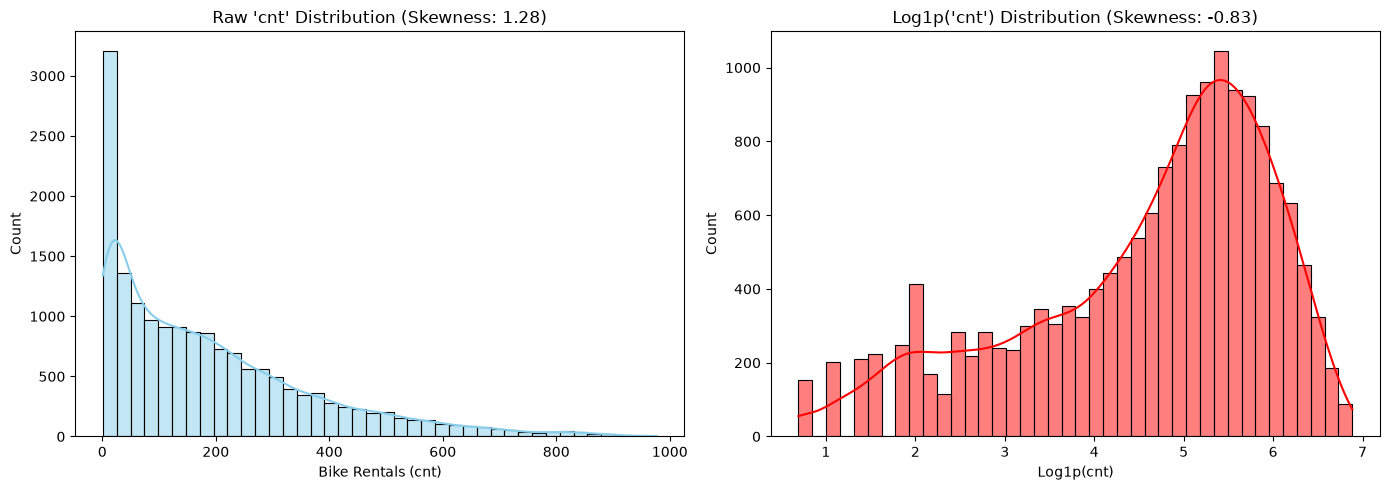

C:\Users\alexa\AppData\Local\Temp\ipykernel_4576\4201920241.py:97: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data = df, x = "weathersit", y = self.target_col, ax = axes[1], palette = "Set2")


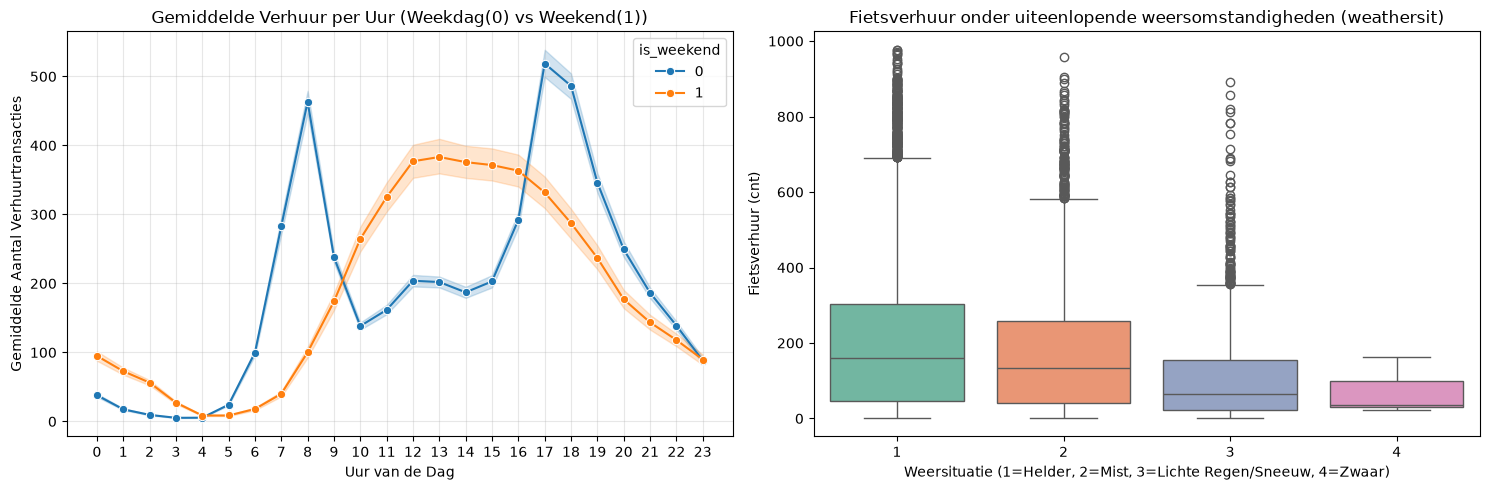

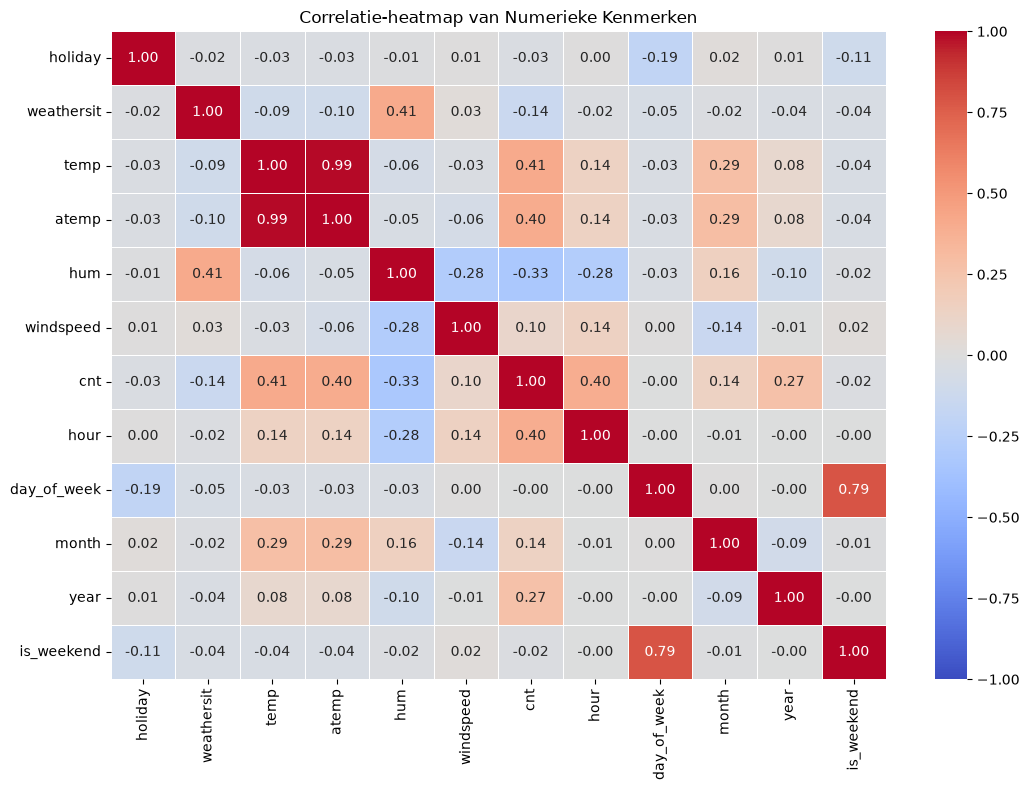

In [145]:
# Initialiseer de feature-engineer en EDA-analyzer 
eda = EDAAnalyzer(datetime_col = "date_hour", target_col = "cnt") 
time_eng = TimeFeatureEngineer(datetime_col = "date_hour") 

# Controleer hoe de train- en testsets in de tijd zijn opgesplitst 
eda.inspect_time_split(train_df, test_df) 

# Creeer kalendarkenmerken voor zowel de trainings- als de testset 
train_df = time_eng.extract_calendar_features(train_df) 
test_df = time_eng.extract_calendar_features(test_df) 

# Analyseer de verdeling en de scheefheid van de doelvariabele 
eda.plot_target_distribution(train_df) 

# Ontdek de spitsuren per uur en de impact van het weer 
eda.plot_key_relationships(train_df)

# Controleer correlaties tussen kenmerken (vooral temp vs atemp) 
eda.plot_correlation_heatmap(train_df)  

#### **2.4 Belangrijkste bevindingen van de EDA** 

##### Lijngrafiek per uur, uitgesplitst naar weekend vs doordeweekse dagen:
##### 1. Spitsuren & de invloed van het weer: Doordeweekse dagen (is_weekend = 0) vertonen duidelijke, bimodale pieken in het woon-werkverkeer om 08:00 uur (ongeveer 460 verhuurtransacties) en tussen 17:00 en 18:00 uur (ongeveer 515 verhuurtransacties).
##### 2. Weekenden (is_weekend = 1): Toont een enkele, vloeiende curve voor vrijetijdsbesteding, met een piek tussen 12:00 en 16:00 uur (~370–380 verhuurgevallen).

##### Weersituatie Boxplot:
##### 3. Weer (weathersit): Het aantal verhuurde fietsen daalt gestaag naarmate het weer verslechtert, van helder (1) tot lichte regen/sneeuw (3), terwijl er bij zware regen/sneeuw (4) bijna geen waarnemingen zijn.

##### Correlatiematrix voor numerieke kenmerken: 
##### 4. Multicollineariteit & belangrijkste voorspellers: 'temp' en 'atemp' vertonen een vrijwel identieke correlatie van 0,99. Het behouden van beide zorgt voor redundantie / 'overfitten' in lineaire modellen; het is daarom raadzaam om te onderzoeken of er een van kunt weglaten.
##### 5. De sterkste lineaire correlaties met 'cnt' zijn temp (0,41), atemp (0,40), hour (0,40), hum (-0,33), year (0,27), weathersit (-0,14) en month (0,14). Merk op dat 'year' een positieve correlatie van 0,27 vertoont; dit betekent dat het totale fietsgebruik tussen 2011 en 2012 aanzienlijk is gegroeid.

##### Histogram van ruwe doelskewness tegen de log1p-getransformeerde doelskewness:
##### 6. Doelscheefheid: De onbewerkte variabele 'cnt' is sterk rechtsscheef (scheefheid = 1,28), waarbij in de meeste uren minder dan 200 verhuurtransacties plaatsvinden, met een lange staart die doorloopt tot ongeveer 950.
##### 7. Het toepassen van np.log1p(cnt) reduceert de scheefheid tot -0,83 en maakt de verdeling aanzienlijk symmetrischer; dit helpt regressiemodellen om patronen te herkennen, zowel voor perioden met een lage vraag als voor piekuren met een hoge vraag.

### 3. **Data opschonen en voorbereiden**

In [147]:
# Initialiseer de DataPreparer
preparer = DataPreparer(datetime_col = "date_hour", target_col = "cnt") 

# Voer anomaliecontroles uit op zowel de trainings- als de testsets
preparer.check_anomalies(train_df, name = "Train")
preparer.check_anomalies(test_df, name = "Test")

# Anomalieën opschonen en de redundante variabele 'atemp' verwijderen (correlatie van 0,99 met 'temp')
train_clean = preparer.clean_data(train_df, drop_atemp=True)
test_clean = preparer.clean_data(test_df, drop_atemp=True)

# Creëer een 'future validation'-splitsing van 19 dagen (die overeenkomt met de testset van 19 dagen)
X_train, X_val, y_train, y_val = preparer.create_time_validation_split(train_clean, val_days=19, use_log_target=True) 

# Bouw je 'lekvrije' preprocessor (klaar om te worden geïntegreerd in elke model-pipeline uit Opdracht 3)
# Stel scale_numeric=True in voor Ridge/Lasso/SVR, of False voor Random Forest/LightGBM
preprocessor = preparer.build_preprocessor(X_train, scale_numeric = True) 


--- ANOMALY & SUMMARY CHECK (Train) ---


,min,50%,mean,max,std
date_hour,2011-01-01 00:00:00,2011-12-18 06:00:00,2011-12-18 02:20:08.294764,2012-11-30 23:00:00,NaN
holiday,0.0,0.0,0.028671,1.0,0.166885
weathersit,1.0,1.0,1.41558,4.0,0.637298
temp,0.02,0.52,0.504745,1.0,0.192369
atemp,0.0,0.5,0.482608,1.0,0.171557
hum,0.0,0.62,0.624756,1.0,0.193227
windspeed,0.0,0.194,0.19031,0.8507,0.121915
cnt,1.0,143.0,190.477009,977.0,182.026755
hour,0.0,12.0,11.547875,23.0,6.914199
day_of_week,0.0,3.0,3.008776,6.0,1.998538


Rows with hum == 0: 22
Rows with windspeed == 0: 2072

--- ANOMALY & SUMMARY CHECK (Test) ---


,min,50%,mean,max,std
date_hour,2012-12-01 00:00:00,2012-12-10 11:30:00,2012-12-10 11:30:00,2012-12-19 23:00:00,NaN
holiday,0.0,0.0,0.0,0.0,0.0
weathersit,1.0,2.0,1.592105,3.0,0.607882
temp,0.16,0.36,0.360132,0.6,0.079432
atemp,0.1818,0.3636,0.363691,0.6212,0.076354
hum,0.33,0.75,0.714868,1.0,0.177732
windspeed,0.0,0.1343,0.157639,0.4925,0.106499
hour,0.0,11.5,11.5,23.0,6.929789
day_of_week,0.0,3.0,2.947368,6.0,2.091709
month,12.0,12.0,12.0,12.0,0.0


Rows with hum == 0: 0
Rows with windspeed == 0: 72

Train split: 2011-01-01 00:00:00 to 2012-11-11 23:00:00 (n=16182)
Val split:   2012-11-12 00:00:00 to 2012-11-30 23:00:00 (n=455)


### **4. Time Series Feature Engineering**

In [156]:
!pip install statsmodels 

Defaulting to user installation because normal site-packages is not writeable
   ---------------------------------------- 0.0/11.3 MB ? eta -:--:--
   -- ------------------------------------- 0.8/11.3 MB 6.3 MB/s eta 0:00:02
   -------- ------------------------------- 2.4/11.3 MB 6.9 MB/s eta 0:00:02
   ------------- -------------------------- 3.9/11.3 MB 7.1 MB/s eta 0:00:02
   -------------------- ------------------- 5.8/11.3 MB 7.4 MB/s eta 0:00:01
   ------------------------- -------------- 7.3/11.3 MB 7.5 MB/s eta 0:00:01
   ------------------------------ --------- 8.7/11.3 MB 7.3 MB/s eta 0:00:01
   ---------------------------------- ----- 9.7/11.3 MB 6.9 MB/s eta 0:00:01
   ---------------------------------------  11.3/11.3 MB 6.9 MB/s eta 0:00:01
   ---------------------------------------- 11.3/11.3 MB 6.7 MB/s  0:00:01

   ---------------------------------------- 0/5 [wrapt]
   ---------------------------------------- 0/5 [wrapt]
   -------- ------------------------------- 1/5


[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: C:\Users\alexa\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


In [158]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf


In [169]:
class TimeSeriesAnalyzerAndEngineer:
    """ Voert tijdreeksdiagnostiek uit (trends, Fourier, ACF/PACF) en ontwikkelt kenmerken (feature engineering)."""
    
    def __init__(self, datetime_col: str = "date_hour", target_col: str = "cnt"):
        self.datetime_col = datetime_col
        self.target_col = target_col 
        
    # TRENDS 
    def plot_trends(self, df: pd.DataFrame): 
        """ Geeft onbewerkte uurgegevens weer, inclusief voortschrijdende gemiddelden over 7 en 30 dagen, om trends zichtbaar te maken."""
        ts = df.set_index(self.datetime_col)[self.target_col] 
        rolling_7d = ts.rolling(window = 24 * 7, min_periods = 1).mean() 
        rolling_30d = ts.rolling(window = 24 * 30, min_periods = 1).mean() 
        
        plt.figure(figsize = (15, 5)) 
        plt.plot(ts.index, ts, alpha = 0.2, color = "gray", label = "Verhuur per Uur (Onbewerkt)")
        plt.plot(rolling_7d.index, rolling_7d, color = "green", linewidth = 1.5, label = "7-day Rolling Mean")
        plt.plot(rolling_30d.index, rolling_30d, color = "r", linewidth = 2.5, label = "30-day Rolling Mean")
        plt.title("Langetermijntrend & seizoensinvloeden bij fietsverhuur (2011 - 2012)")
        plt.xlabel("Datum")
        plt.ylabel("Verhuur (cnt)")
        plt.legend()
        plt.grid(True, alpha = 0.3)
        plt.tight_layout() 
        plt.show() 
        
    def add_trend_features(self, df: pd.DataFrame, start_date: pd.Timestamp):
        """ Creëert een continue tijdindex (aantal uren sinds de startdatum) om langetermijngroei in kaart te brengen."""
        df = df.copy() 
        df["time_index"] = (df[self.datetime_col] - start_date).dt.total_seconds() / 3600.0 
        return df 
    
    # FOURIER SEASONALITY 
    def plot_fourier_spectrum(self, df: pd.DataFrame):
        """ Berekent Fast Fourier Transform (FFT) om dominante seizoensgebonden perioden te identificeren."""
        signal = df[self.target_col].values - df[self.target_col].mean() 
        fft_vals = np.abs(np.fft.rfft(signal)) 
        freqs = np.fft.rfftfreq(len(signal), d = 1.0) # d = 1.0 hour 
        
        # Zet frequenties (> 0) om in perioden in uren
        valid = freqs > 0 
        periods = 1.0 / freqs[valid] 
        power = fft_vals[valid]  
        
        plt.figure(figsize = (14, 5)) 
        plt.plot(periods, power, color = "steelblue", linewidth = 1.2) 
        plt.xscale("log") 
        
        # Markeer de belangrijkste verwachte cycli
        for p, label in [(12, "12h (Commute)"), (24, "24h (Daily)"), (168, "168h (Weekly)"), (8760, "8760h (Yearly)")]:
            plt.axvline(p, color="r", linestyle="--", alpha=0.8)
            plt.text(p * 1.05, power.max() * 0.85, label, rotation=90, verticalalignment="top", fontsize=9)
            
        plt.title("Fourier Power Spectrum: Dominant Seasonal Cycles (Log Period Scale)")
        plt.xlabel("Period (Hours, Log Scale)")
        plt.ylabel("Fourier Amplitude (Power)") 
        plt.grid(True, alpha = 0.3) 
        plt.tight_layout() 
        plt.show() 
        
    def add_fourier_features(self, df: pd.DataFrame, periods: list[int]) -> pd.DataFrame: 
        """ Voegt vloeiende sinus- en cosinusparen toe voor elke dominante Fourier-periode."""
        df = df.copy() 
        if "time_index" not in df.columns:
            raise ValueError("Run add_trend_features() first so 'time_index' exists.")
        
        for p in periods: 
            angle = 2 * np.pi * df["time_index"] / p 
            df[f"sin_{p}h"] = np.sin(angle) 
            df[f"cos_{p}h"] = np.cos(angle) 
        
    def add_fourier_features(
        self, df: pd.DataFrame, periods: tuple[int, ...] = (24, 168, 8760)
    ) -> pd.DataFrame:
        """Voegt sinus- en cosinuskenmerken toe voor elke Fourier-periode."""
        df = df.copy()

        if "time_index" not in df.columns:
            raise ValueError("Run add_trend_features() first so 'time_index' exists.")

        for p in periods:
            angle = 2 * np.pi * df["time_index"] / p
            df[f"sin_{p}h"] = np.sin(angle)
            df[f"cos_{p}h"] = np.cos(angle)

        return df 
        
    # CYCLES & AUTOCORRELATION 
    def plot_autocorrelation(self, df: pd.DataFrame, max_lags: int = 168) -> None:
        """ Geeft ACF- en PACF-plots weer tot max_lags (168 uur = 1 volledige week)."""
        fig, axes = plt.subplots(2, 1, figsize=(15, 8))

        plot_acf(df[self.target_col], lags=max_lags, ax=axes[0], color="steelblue")
        axes[0].set_title(f"Autocorrelation Function (ACF) up to {max_lags} Hours (1 Week)")
        axes[0].set_xlabel("Lag (Hours)")

        plot_pacf(df[self.target_col], lags=72, ax=axes[1], color="seagreen", method="ywm")
        axes[1].set_title("Partial Autocorrelation Function (PACF) up to 72 Hours (3 Days)")
        axes[1].set_xlabel("Lag (Hours)")

        plt.tight_layout()
        plt.show()   
        
     # OTHER TIME-BASED & INTERACTION FEATURES 
    def add_domain_time_features(self, df: pd.DataFrame) -> pd.DataFrame:
        """ Voegt markeringen voor de spits toe, evenals tijdsgebonden categorieën en interacties met weers- en kalendergegevens."""
        df = df.copy()
    
        # Definieer 'workingday': geen weekend en geen feestdag
        df["workingday"] = ((df["is_weekend"] == 0) & (df["holiday"] == 0)).astype(int)
        
        # Ochtendspits (7-9 uur) en avondspits (16-19 uur) op werkdagen
        is_commute_hour = df["hour"].isin([7, 8, 9, 16, 17, 18, 19])
        df["is_rush_hour"] = (is_commute_hour & (df["workingday"] == 1)).astype(int)

        # Nachtindicator (00:00 - 05:00), wanneer de vraag het laagst is
        df["is_night"] = df["hour"].isin([0, 1, 2, 3, 4, 5]).astype(int)

        # Interactie: warm weer stimuleert recreatief fietsen in het weekend op een andere manier dan woon-werkverkeer.
        df["temp_x_workingday"] = df["temp"] * df["workingday"]
        return df
    
            
        
        

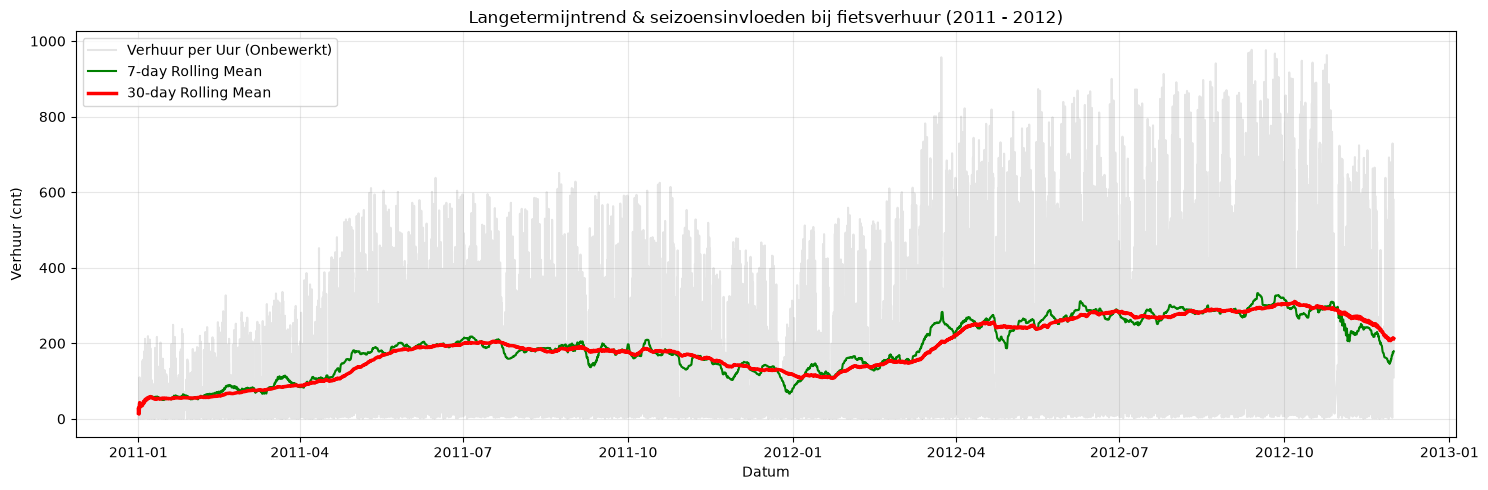

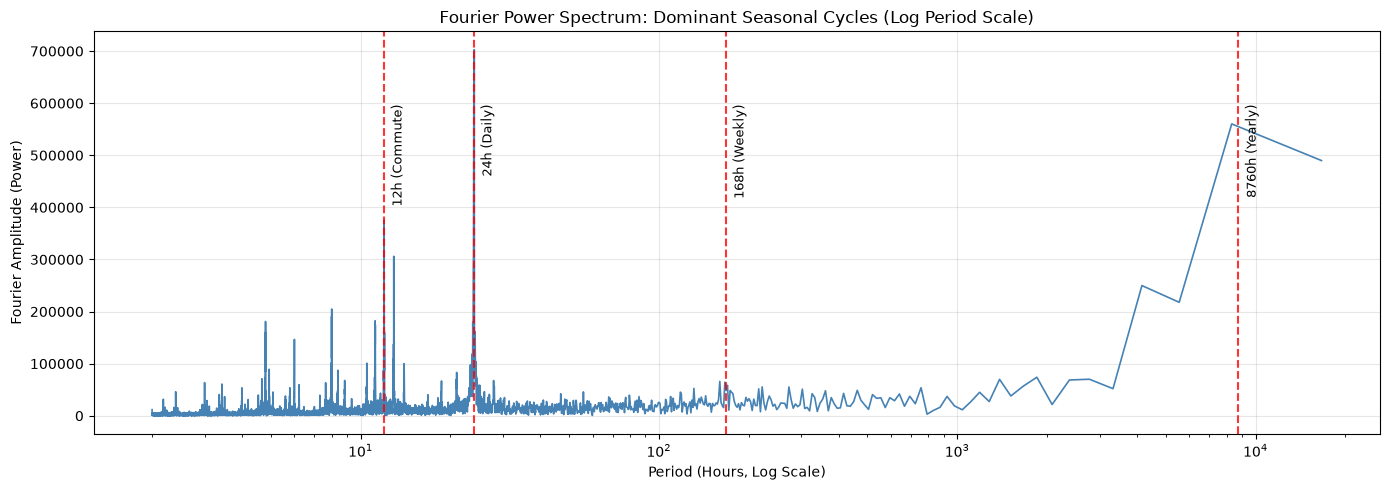

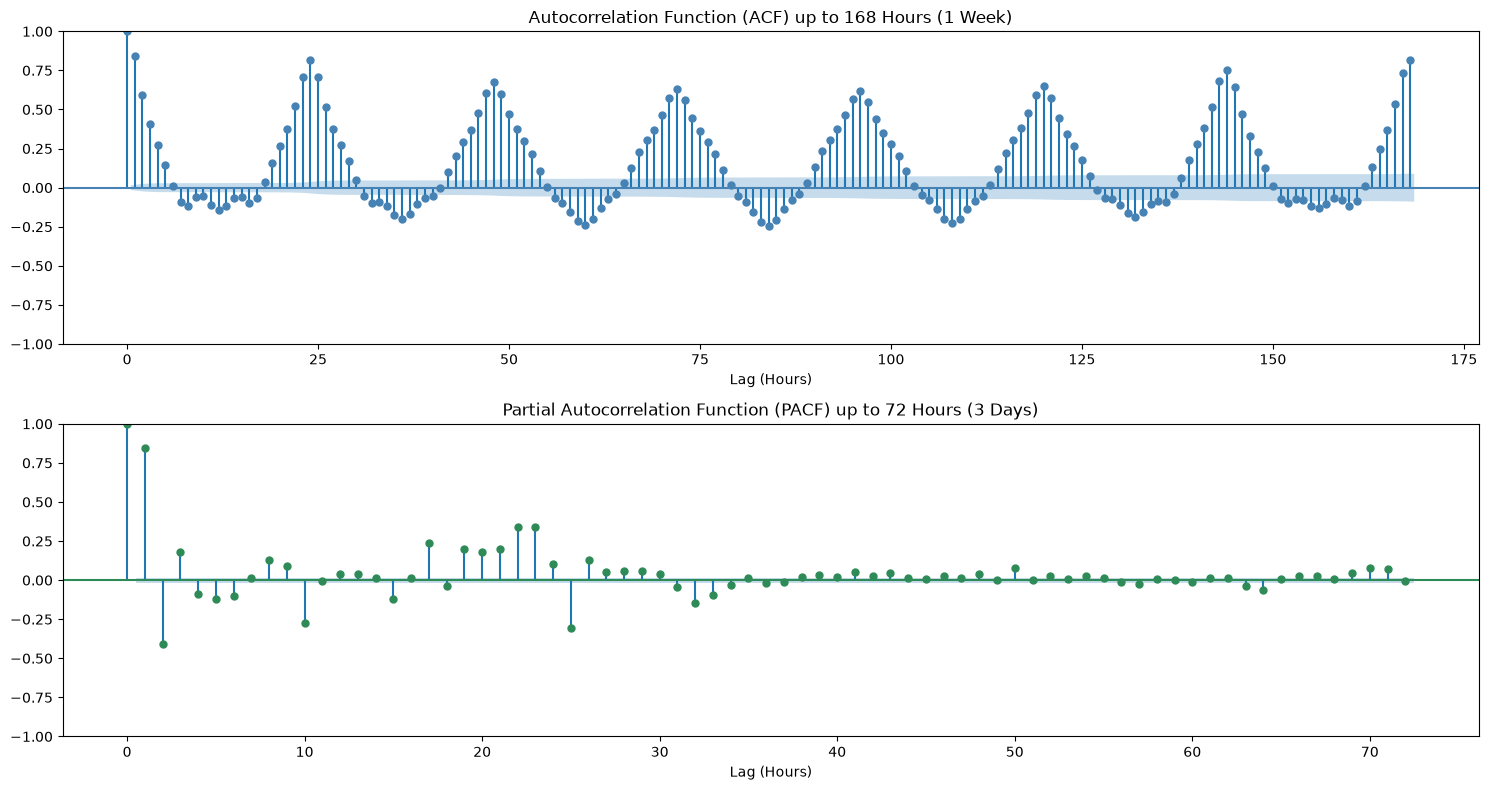

New shape of train_fe: (16637, 25)
New shape of test_fe: (456, 24)


In [170]:
ts_engineer = TimeSeriesAnalyzerAndEngineer(datetime_col = "date_hour", target_col = "cnt") 

# Visuele & wiskundige verkenning (Opdracht 2 Onderzoek)
ts_engineer.plot_trends(train_clean)
ts_engineer.plot_fourier_spectrum(train_clean)
ts_engineer.plot_autocorrelation(train_clean, max_lags = 168) 

# Pas de geconstrueerde kenmerken toe op zowel de trainings- als de testset
start_date = train_clean["date_hour"].min() 

train_fe = ts_engineer.add_trend_features(train_clean, start_date = start_date) 
test_fe = ts_engineer.add_trend_features(test_clean, start_date = start_date) 

train_fe = ts_engineer.add_fourier_features(train_fe, periods = [12, 24, 168, 8760]) 
test_fe = ts_engineer.add_fourier_features(test_fe, periods = [12, 24, 168, 8760]) 

train_fe = ts_engineer.add_domain_time_features(train_fe)
test_fe = ts_engineer.add_domain_time_features(test_fe)

print("New shape of train_fe:", train_fe.shape) 
print("New shape of test_fe:", test_fe.shape) 